# P-1 Random Forest Regressor with 5-Lag Telemetry and Context History

This notebook fits the final P-1 Random Forest forecasting model using the previous **5 observations** of both telemetry and context.

The earlier one-lag Random Forest used

$$
X_t =
[y_{t-1}, \mathbf{z}_{t-1}],
$$

where $\mathbf{z}_{t-1}$ contains the 24 context/command features.

The final RF(5) model uses

$$
X_t =
[
y_{t-1}, \mathbf{z}_{t-1},
y_{t-2}, \mathbf{z}_{t-2},
\ldots,
y_{t-5}, \mathbf{z}_{t-5}
].
$$

Because each lag contributes 1 telemetry variable and 24 context variables, the model has

$$
5(1+24)=125
$$

predictors.

The lag length was evaluated separately using training-only time-series cross-validation. Although lag 10 produced the numerically lowest mean validation MAE, lag 5 was within one standard error of that minimum and was retained as the simpler specification.

After the Random Forest produces telemetry forecasts, the anomaly-detection stage is kept fixed using the shared `detection.py` Telemanom post-prediction procedure.

**Important:** the Random Forest lag length and the Telemanom `history_length` parameter are different concepts.

- Random Forest history supplied to the forecaster: **5 lags**
- Telemanom detection `history_length`: **250**, retained to preserve the common P-1 prediction alignment and detector behavior


## 1. Import packages and locate the repository

This notebook is intended to run from the repository root or from its `Models` folder.


In [43]:
# Standard libraries
import ast
import sys
from pathlib import Path

# Data and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Random Forest regression and validation
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# Locate the repository root.
# ------------------------------------------------------------
repo_dir = Path.cwd().resolve()

if not (repo_dir / "detection.py").is_file():
    repo_dir = repo_dir.parent

if not (repo_dir / "detection.py").is_file():
    raise FileNotFoundError(
        "Could not find detection.py. Run this notebook from the "
        "fall-2026-spacecraft-sensors repository or its Models folder."
    )

if str(repo_dir) not in sys.path:
    sys.path.insert(0, str(repo_dir))

import detection

print("Repository root:", repo_dir)
print("Detection module:", repo_dir / "detection.py")


Repository root: /Users/jezercahodaj/Desktop/Erdos-Project/fall-2026-spacecraft-sensors
Detection module: /Users/jezercahodaj/Desktop/Erdos-Project/fall-2026-spacecraft-sensors/detection.py


## 2. Load P-1 data and anomaly labels

For P-1:

- column 0 is the telemetry signal,
- columns 1–24 are the context/command variables.

The official training set is used for model fitting and time-series cross-validation. The labeled anomaly intervals are not used in model fitting or hyperparameter selection.


In [44]:
data_dir = repo_dir / "data" / "data"

p1_train = np.load(data_dir / "train" / "P-1.npy")
p1_test = np.load(data_dir / "test" / "P-1.npy")
labels = pd.read_csv(data_dir / "labeled_anomalies.csv")

print("Training shape:", p1_train.shape)
print("Test shape:", p1_test.shape)
print("Telemetry columns:", 1)
print("Context columns:", p1_train.shape[1] - 1)


Training shape: (2872, 25)
Test shape: (8505, 25)
Telemetry columns: 1
Context columns: 24


## 3. Define the 5-lag predictor construction

For each target telemetry value $y_t$, the Random Forest receives the previous 5 complete P-1 rows:

$$
[
y_{t-1},z_{1,t-1},\ldots,z_{24,t-1},
y_{t-2},z_{1,t-2},\ldots,z_{24,t-2},
\ldots,
y_{t-5},z_{1,t-5},\ldots,z_{24,t-5}
].
$$

This creates

$$
5\times 25 = 125
$$

predictors.

The function below constructs these lagged predictors using only observations that occur before the target time.


In [45]:
N_LAGS = 5
N_CONTEXT = p1_train.shape[1] - 1

def make_lagged_matrix(data, target_indices, n_lags):
    """Construct lagged predictors for selected target indices.

    Each target at time t receives the full row of predictors from
    t-1, t-2, ..., t-n_lags.

    Column 0 is telemetry and columns 1: are context variables.
    """
    target_indices = np.asarray(target_indices)

    if np.min(target_indices) < n_lags:
        raise ValueError(
            "Every target index must be at least n_lags."
        )

    lag_blocks = []
    predictor_names = []

    for lag in range(1, n_lags + 1):
        lag_blocks.append(data[target_indices - lag, :])

        predictor_names.append(f"telemetry_lag{lag}")
        predictor_names.extend([
            f"context_{j}_lag{lag}"
            for j in range(1, data.shape[1])
        ])

    X = np.hstack(lag_blocks)

    return X, predictor_names


# Training targets begin at index N_LAGS so all prior lagged rows exist.
train_target_indices = np.arange(
    N_LAGS,
    len(p1_train)
)

X_train, predictor_names = make_lagged_matrix(
    p1_train,
    train_target_indices,
    N_LAGS
)

y_train = p1_train[
    train_target_indices,
    0
]

print("Number of lags:", N_LAGS)
print("Training predictor matrix shape:", X_train.shape)
print("Training response shape:", y_train.shape)
print("Number of predictors:", X_train.shape[1])

assert X_train.shape[1] == N_LAGS * p1_train.shape[1]
assert X_train.shape[0] == len(y_train)


Number of lags: 5
Training predictor matrix shape: (2867, 125)
Training response shape: (2867,)
Number of predictors: 125


## 4. Why use 5 lags?

The earlier one-lag Random Forest received only the immediately previous telemetry/context observation.

Adding several lags allows the model to represent short-term temporal patterns such as:

- telemetry rising or falling over several observations,
- short oscillatory patterns,
- recent changes in context variables,
- nonlinear interactions between recent telemetry history and context history.

A Random Forest does not have recurrent memory like an LSTM, so temporal history must be supplied explicitly as lagged predictor columns.

Lag length was evaluated separately using training-only time-series cross-validation. Lag 10 had the lowest mean validation MAE, but lag 5 was within one standard error of the minimum and therefore provided a simpler model with statistically comparable forecasting performance.

The final model therefore uses **5 lags**, corresponding to 125 predictors.


## 5. Random Forest candidate settings

To make this experiment comparable with the earlier one-lag Random Forest, the same small hyperparameter grid is used.

The number of trees is fixed at 200 during cross-validation.

The candidate settings vary:

- `max_depth`,
- `min_samples_leaf`,
- `max_features`.

The anomaly labels are not used for hyperparameter selection.


In [46]:
rf_candidates = [
    {
        "max_depth": 5,
        "min_samples_leaf": 1,
        "max_features": "sqrt"
    },
    {
        "max_depth": 10,
        "min_samples_leaf": 1,
        "max_features": "sqrt"
    },
    {
        "max_depth": 10,
        "min_samples_leaf": 5,
        "max_features": "sqrt"
    },
    {
        "max_depth": None,
        "min_samples_leaf": 5,
        "max_features": "sqrt"
    },
    {
        "max_depth": 10,
        "min_samples_leaf": 5,
        "max_features": 1.0
    },
    {
        "max_depth": None,
        "min_samples_leaf": 5,
        "max_features": 1.0
    }
]

print("Candidate configurations:", len(rf_candidates))


Candidate configurations: 6


## 6. Time-series cross-validation

The candidate Random Forest configurations are compared using 5-fold `TimeSeriesSplit`.

This preserves temporal ordering: each validation block occurs after the training observations used to fit that fold.

The selection metric is mean absolute error:

$$
MAE =
\frac{1}{n}
\sum_{i=1}^{n}
|y_i-\hat y_i|.
$$

The configuration with the lowest mean validation MAE is selected.


In [47]:
tscv = TimeSeriesSplit(n_splits=5)

cv_rows = []

for candidate_id, params in enumerate(
    rf_candidates,
    start=1
):
    for fold, (fit_idx, val_idx) in enumerate(
        tscv.split(X_train),
        start=1
    ):
        model_cv = RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1,
            **params
        )

        model_cv.fit(
            X_train[fit_idx],
            y_train[fit_idx]
        )

        val_predictions = model_cv.predict(
            X_train[val_idx]
        )

        fold_mae = mean_absolute_error(
            y_train[val_idx],
            val_predictions
        )

        cv_rows.append({
            "candidate": candidate_id,
            "fold": fold,
            "max_depth": params["max_depth"],
            "min_samples_leaf": params["min_samples_leaf"],
            "max_features": params["max_features"],
            "validation_MAE": fold_mae
        })

cv_results = pd.DataFrame(cv_rows)

display(cv_results.head(10))


,candidate,fold,max_depth,min_samples_leaf,max_features,validation_MAE
0,1,1,5.0,1,sqrt,0.182389
1,1,2,5.0,1,sqrt,0.182240
2,1,3,5.0,1,sqrt,0.171344
3,1,4,5.0,1,sqrt,0.171695
4,1,5,5.0,1,sqrt,0.194580
5,2,1,10.0,1,sqrt,0.153192
6,2,2,10.0,1,sqrt,0.143726
7,2,3,10.0,1,sqrt,0.138772
8,2,4,10.0,1,sqrt,0.140074
9,2,5,10.0,1,sqrt,0.152816


## 7. Select the best Random Forest configuration

The candidate with the lowest mean validation MAE across the five time-series folds is selected.


In [48]:
cv_summary = (
    cv_results
    .groupby(
        [
            "candidate",
            "max_depth",
            "min_samples_leaf",
            "max_features"
        ],
        dropna=False,
        as_index=False
    )
    .agg(
        mean_validation_MAE=("validation_MAE", "mean"),
        sd_validation_MAE=("validation_MAE", "std")
    )
    .sort_values("mean_validation_MAE")
    .reset_index(drop=True)
)

display(cv_summary)

best_candidate_id = int(
    cv_summary.loc[0, "candidate"]
)

best_params = rf_candidates[
    best_candidate_id - 1
]

print("Selected candidate:", best_candidate_id)
print("Selected parameters:", best_params)
print(
    "Mean validation MAE:",
    cv_summary.loc[0, "mean_validation_MAE"]
)


,candidate,max_depth,min_samples_leaf,max_features,mean_validation_MAE,sd_validation_MAE
0,5,10.0,5,1.0,0.111660,0.008817
1,6,NaN,5,1.0,0.112021,0.008694
2,2,10.0,1,sqrt,0.145716,0.006898
3,4,NaN,5,sqrt,0.170741,0.016483
4,3,10.0,5,sqrt,0.171409,0.016276
5,1,5.0,1,sqrt,0.180450,0.009568


Selected candidate: 5
Selected parameters: {'max_depth': 10, 'min_samples_leaf': 5, 'max_features': 1.0}
Mean validation MAE: 0.1116597943892215


## 8. Fit the final 5-lag Random Forest

The selected Random Forest structural settings are fitted using all available 5-lag training observations.

The final model uses 300 trees.


In [49]:
rf5_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    **best_params
)

rf5_model.fit(
    X_train,
    y_train
)

print("Final 5-lag Random Forest fitted.")
print("Number of trees:", len(rf5_model.estimators_))
print("Selected parameters:", best_params)


Final 5-lag Random Forest fitted.
Number of trees: 300
Selected parameters: {'max_depth': 10, 'min_samples_leaf': 5, 'max_features': 1.0}


## 9. Inspect feature importance

With 125 predictors, looking only at individual feature importances can be difficult.

Two summaries are useful:

1. the most important individual lagged predictors,
2. total importance aggregated by lag.

If the model meaningfully uses longer history, some importance should appear beyond lag 1.


Top 20 individual lagged predictors:


,predictor,importance,lag,feature
0,telemetry_lag1,0.865968,1,telemetry
1,telemetry_lag5,0.028001,5,telemetry
2,telemetry_lag4,0.022224,4,telemetry
3,telemetry_lag2,0.020592,2,telemetry
4,context_22_lag1,0.015689,1,context_22
5,telemetry_lag3,0.013371,3,telemetry
6,context_21_lag1,0.011106,1,context_21
7,context_19_lag2,0.003488,2,context_19
8,context_19_lag3,0.002293,3,context_19
9,context_17_lag1,0.002293,1,context_17


,lag,importance
0,1,0.900948
1,2,0.027955
2,3,0.018135
3,4,0.023751
4,5,0.029211


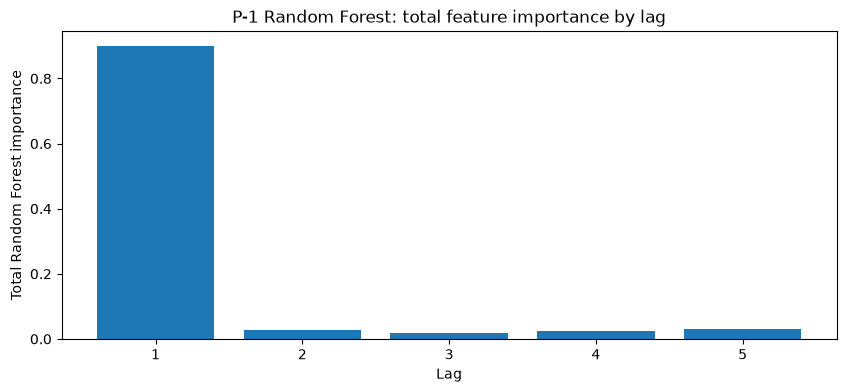

In [50]:
# Individual feature importance.
importance_table = pd.DataFrame({
    "predictor": predictor_names,
    "importance": rf5_model.feature_importances_
})

# Add lag and feature-group metadata.
lag_values = []
feature_types = []

for lag in range(1, N_LAGS + 1):
    lag_values.extend(
        [lag] * p1_train.shape[1]
    )
    feature_types.extend(
        ["telemetry"]
        + [f"context_{j}" for j in range(1, N_CONTEXT + 1)]
    )

importance_table["lag"] = lag_values
importance_table["feature"] = feature_types

importance_table = (
    importance_table
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 20 individual lagged predictors:")
display(importance_table.head(20))

# Aggregate importance by lag.
importance_by_lag = (
    importance_table
    .groupby("lag", as_index=False)["importance"]
    .sum()
    .sort_values("lag")
)

display(importance_by_lag)

fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(
    importance_by_lag["lag"],
    importance_by_lag["importance"]
)

ax.set(
    title="P-1 Random Forest: total feature importance by lag",
    xlabel="Lag",
    ylabel="Total Random Forest importance"
)

ax.set_xticks(range(1, N_LAGS + 1))
plt.show()


## 10. Generate aligned P-1 test forecasts

To compare directly with the one-lag Random Forest, ARX, and the authors' saved LSTM predictions, the forecast range is kept unchanged:

- first forecasted test index: 250,
- last forecasted test index: 8494,
- number of forecasts: 8,245.

For every forecast at time $t$, the Random Forest now receives the previous 5 complete telemetry/context rows.

The fact that the first forecast is at test index 250 means all 5 required lags are available entirely within the test sequence.

Again, **5 is the Random Forest lag length**, whereas **250 is the P-1 forecast/detection alignment used by Telemanom**.


In [51]:
# Preserve the P-1 forecast alignment used in the other models.
HISTORY_LENGTH = 250
N_PREDICTIONS = 10

n_forecasts = (
    len(p1_test)
    - HISTORY_LENGTH
    - N_PREDICTIONS
)

prediction_indices = np.arange(
    HISTORY_LENGTH,
    HISTORY_LENGTH + n_forecasts
)

# Construct 5-lag test predictors for exactly the same target indices.
X_test, test_predictor_names = make_lagged_matrix(
    p1_test,
    prediction_indices,
    N_LAGS
)

assert predictor_names == test_predictor_names

rf5_predictions = rf5_model.predict(
    X_test
)

actual_aligned = p1_test[
    prediction_indices,
    0
]

rf5_test_mae = mean_absolute_error(
    actual_aligned,
    rf5_predictions
)

print("Number of forecasts:", len(rf5_predictions))
print("First forecasted test index:", prediction_indices[0])
print("Last forecasted test index:", prediction_indices[-1])
print("Aligned test MAE:", rf5_test_mae)


Number of forecasts: 8245
First forecasted test index: 250
Last forecasted test index: 8494
Aligned test MAE: 0.09918614827351466


## 11. Plot actual and predicted telemetry


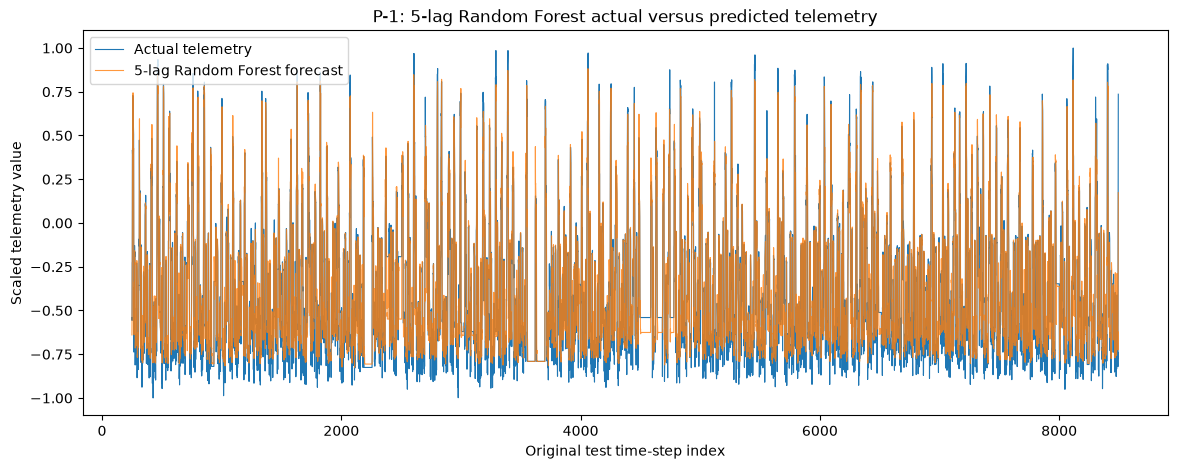

In [52]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    prediction_indices,
    actual_aligned,
    linewidth=0.8,
    label="Actual telemetry"
)

ax.plot(
    prediction_indices,
    rf5_predictions,
    linewidth=0.8,
    alpha=0.8,
    label="5-lag Random Forest forecast"
)

ax.set(
    title="P-1: 5-lag Random Forest actual versus predicted telemetry",
    xlabel="Original test time-step index",
    ylabel="Scaled telemetry value"
)

ax.legend()
plt.show()


## 12. Apply the same Telemanom post-prediction detection procedure

Nothing in `detection.py` is changed for this experiment.

The same settings used for the one-lag Random Forest and ARX are retained:

- `history_length = 250`,
- `n_predictions = 10`,
- `batch_size = 70`,
- `window_size = 30`,
- `smoothing_perc = 0.05`,
- `error_buffer = 100`,
- `p = 0.13`,
- `initial_adjustment = True`,
- `initial_ignore = 500`.

Therefore, the intended experimental change is the amount of temporal history supplied to the Random Forest forecaster.


In [53]:
rf5_detection = detection.detect_anomalies(
    test_data=p1_test,
    predictions=rf5_predictions,
    history_length=HISTORY_LENGTH,
    n_predictions=N_PREDICTIONS,
    target_column=0,
    batch_size=70,
    window_size=30,
    smoothing_perc=0.05,
    error_buffer=100,
    p=0.13,
    initial_adjustment=True,
    initial_ignore=500
)

print("Detected 5-lag Random Forest alert intervals:")
print(rf5_detection["detected_intervals"])

print()
print(
    "Number of detected intervals:",
    len(rf5_detection["detected_intervals"])
)


Detected 5-lag Random Forest alert intervals:
[(2137, 2559), (3540, 3749)]

Number of detected intervals: 2


## 13. Examine raw and smoothed forecast errors

The raw forecast error is

$$
e_t = |y_t-\hat y_t|.
$$

The Telemanom post-processing procedure operates on smoothed versions of these errors.


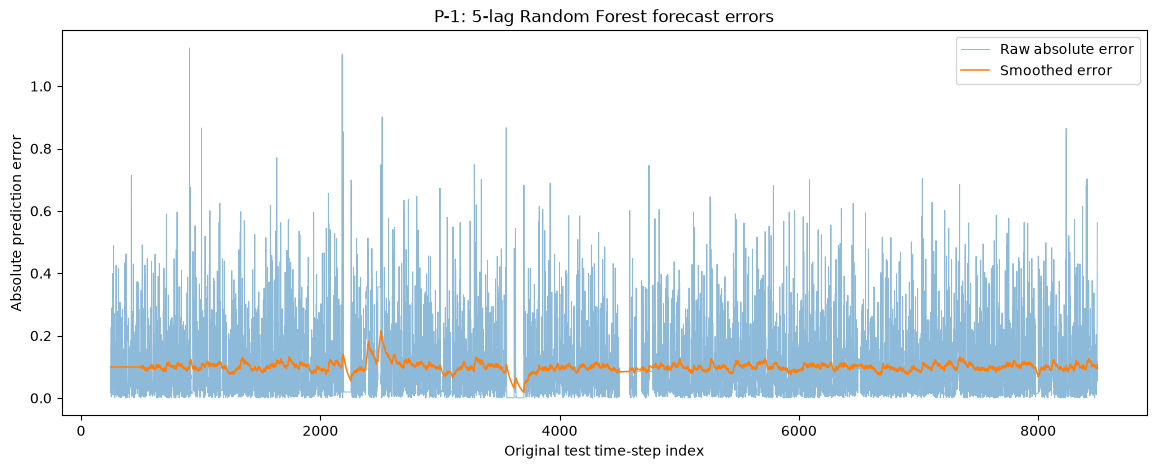

In [54]:
error_indices = rf5_detection["prediction_indices"]

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    error_indices,
    rf5_detection["raw_errors"],
    linewidth=0.7,
    alpha=0.5,
    label="Raw absolute error"
)

ax.plot(
    error_indices,
    rf5_detection["smoothed_errors"],
    linewidth=1.1,
    label="Smoothed error"
)

ax.set(
    title="P-1: 5-lag Random Forest forecast errors",
    xlabel="Original test time-step index",
    ylabel="Absolute prediction error"
)

ax.legend()
plt.show()


## 14. Load the labeled P-1 anomaly events

The anomaly labels are introduced only after the forecasting model and detector have produced their results.


In [55]:
p1_label_rows = labels.loc[
    labels["chan_id"] == "P-1"
]

if p1_label_rows.empty:
    raise ValueError("No anomaly labels found for P-1.")

labeled_intervals = sorted({
    (int(start), int(end))
    for sequences in p1_label_rows["anomaly_sequences"]
    for start, end in ast.literal_eval(sequences)
})

print("Labeled P-1 events:")
print(labeled_intervals)

print()
print(
    "Anomaly class information:",
    p1_label_rows["class"].tolist()
)


Labeled P-1 events:
[(2149, 2349), (3539, 3779), (4536, 4844)]

Anomaly class information: ['[contextual, contextual, contextual]']


## 15. Event-level anomaly detection evaluation

A labeled event counts as detected if at least one predicted alert interval overlaps it.

The main metrics are:

$$
\text{Precision}
=
\frac{TP}{TP+FP},
$$

$$
\text{Recall}
=
\frac{TP}{TP+FN},
$$

and

$$
F_1
=
2
\frac{\text{Precision}\times\text{Recall}}
{\text{Precision}+\text{Recall}}.
$$

We also calculate $F_{0.5}$, which weights precision more heavily.


In [56]:
evaluation = detection.evaluate_event_detection(
    detected_intervals=rf5_detection["detected_intervals"],
    labeled_intervals=labeled_intervals
)

precision = evaluation["precision"]
recall = evaluation["recall"]

beta = 0.5

if np.isnan(precision) or np.isnan(recall):
    f_beta = np.nan
elif beta**2 * precision + recall == 0:
    f_beta = np.nan
else:
    f_beta = (
        (1 + beta**2)
        * precision
        * recall
        / (beta**2 * precision + recall)
    )

print("5-lag Random Forest + Telemanom detection")
print("-------------------------------------------")
print(f"TP: {evaluation['TP']}")
print(f"FP: {evaluation['FP']}")
print(f"FN: {evaluation['FN']}")

if np.isnan(precision):
    print("Precision: undefined (no detected intervals)")
else:
    print(f"Precision: {precision:.1%}")

print(f"Recall: {recall:.1%}")
print(f"F1: {evaluation['f1']:.3f}")

if np.isnan(f_beta):
    print("F0.5: undefined")
else:
    print(f"F0.5: {f_beta:.3f}")


5-lag Random Forest + Telemanom detection
-------------------------------------------
TP: 2
FP: 0
FN: 1
Precision: 100.0%
Recall: 66.7%
F1: 0.800
F0.5: 0.909


## 16. Check which labeled events were detected


In [57]:
event_table = pd.DataFrame({
    "labeled_interval": labeled_intervals,
    "detected": evaluation["detected_event_mask"]
})

display(event_table)


,labeled_interval,detected
0,"(2149, 2349)",True
1,"(3539, 3779)",True
2,"(4536, 4844)",False


## 17. Check which detector branches retained readings

The Telemanom-style detector evaluates both:

- `high errors`,
- `low errors` (the inverted-error branch).

Only windows that retained at least one reading are shown below.


In [58]:
active_windows = rf5_detection["window_results"].loc[
    rf5_detection["window_results"]["retained readings"] > 0
].copy()

display(active_windows)


,window,branch,z,threshold,retained readings
1,0,low errors,2.5,0.127818,213
2,1,high errors,3.0,0.141349,70
4,2,high errors,3.0,0.146671,70
6,3,high errors,2.5,0.154129,70
37,18,low errors,2.5,0.159862,70
39,19,low errors,2.5,0.164498,70
41,20,low errors,2.5,0.168051,70


## 18. Plot labeled events and detected alerts


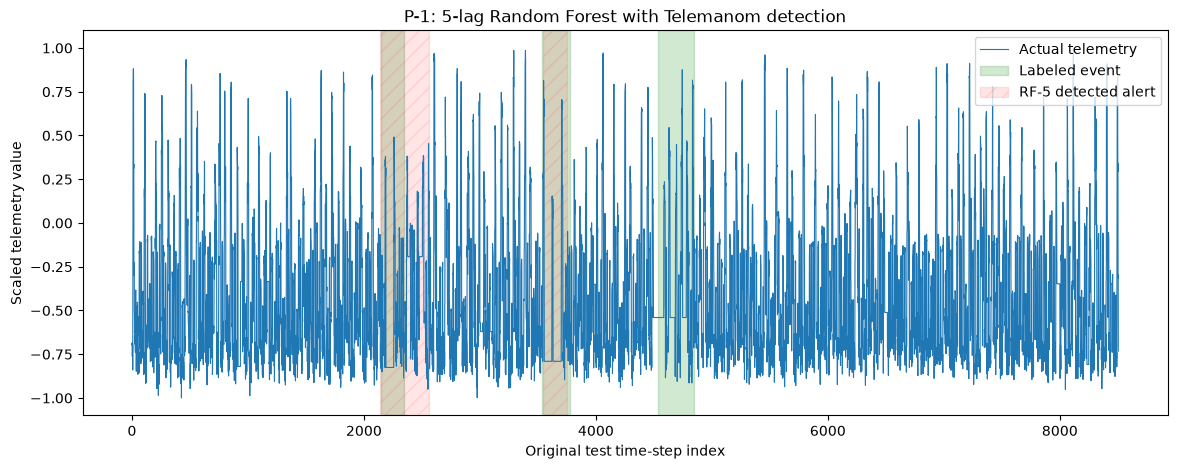

In [59]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    np.arange(len(p1_test)),
    p1_test[:, 0],
    linewidth=0.8,
    label="Actual telemetry"
)

for i, (start, end) in enumerate(labeled_intervals):
    ax.axvspan(
        start,
        end,
        color= "green",
        alpha=0.18,
        label="Labeled event" if i == 0 else None
    )

for i, (start, end) in enumerate(
    rf5_detection["detected_intervals"]
):
    ax.axvspan(
        start,
        end,
        color = "red",
        alpha=0.10,
        hatch="//",
        label="RF-5 detected alert" if i == 0 else None
    )

ax.set(
    title="P-1: 5-lag Random Forest with Telemanom detection",
    xlabel="Original test time-step index",
    ylabel="Scaled telemetry value"
)

ax.legend()
plt.show()


# Interpretation

The final Random Forest model uses **5 lags** of telemetry and all 24 context variables:

$$
\text{RF(5): }
[y_{t-1},\mathbf z_{t-1},\ldots,y_{t-5},\mathbf z_{t-5}]
\longrightarrow
\hat y_t.
$$

This gives

$$
5\times25=125
$$

predictors.

The lag length was selected separately using training-only time-series cross-validation. Lag 10 produced the smallest mean validation MAE, but lag 5 was within one standard error of that minimum and was retained as the simpler specification.

The downstream anomaly detector is unchanged. Therefore, the final comparison is:

| Model | Temporal information supplied to forecaster | P-1 event-detection result |
|---|---|---|
| One-lag Random Forest | 1 telemetry lag + 1 context lag | 0/3 events in the earlier run |
| **RF(5)** | 5 telemetry lags + 5 context lags | **2/3 events, 0 false alerts** |
| Original Telemanom LSTM | long sequence history | 3/3 events under the shared corrected detector |

For RF(5), the first detected alert overlaps the first labeled event but extends beyond its labeled boundaries. Under the project's event-level overlap criterion, it is still counted as a true positive. The second labeled event is also detected, while the third is missed.

An important result from the lag experiments is that lower forecasting MAE did not automatically produce better anomaly detection. In particular, the RF model using 10 lags achieved slightly lower training-CV forecasting error than RF(5), but it did not detect the P-1 anomaly events under the fixed Telemanom detector.

This illustrates the distinction between the two objectives:

$$
\text{forecasting accuracy}
\neq
\text{anomaly-detection effectiveness}.
$$

Telemanom operates on the structure of the forecast residuals, so a forecasting model that predicts anomalous behavior too closely may generate residuals that are not unusual enough to trigger the detector.

## Important limitation

This is still not a fully controlled architecture comparison with the original LSTM.

RF(5) receives five explicitly constructed lagged rows, whereas the original LSTM uses a much longer sequential input and learns an internal nonlinear temporal representation.

Therefore, performance differences may reflect both:

1. the forecasting architecture, and
2. the amount and representation of temporal history.


# Computational cost benchmark

This section estimates the operational computing cost of **RF(5) + Telemanom detection** using the same benchmarking and cloud-cost assumptions used in `Rios_Forecasting_Cost_Comparison.ipynb`.

## Benchmark scope

The benchmark uses the same **8,245 aligned P-1 test targets** evaluated earlier in this notebook.

Three operations are timed separately:

1. **Forecast generation:** reconstruct the model inputs for the aligned P-1 targets and generate predictions.
2. **Detection only:** process the already-generated forecasts through the shared `detection.py` procedure.
3. **Complete pipeline:** generate forecasts and then run the shared detector.

The benchmark excludes:

- data loading,
- imports,
- plotting,
- evaluation against anomaly labels,
- cross-validation and model selection,
- final-model training.

These are batch-processing measurements rather than real-time alert latencies.

Each timed operation is warmed up first. `timeit.autorange()` chooses a suitable number of calls, and the measurement is repeated **7 times**. The notebook reports the median and the 25th/75th percentiles, matching Diego's benchmark procedure.


## Reusable RF(5) forecast operation

The forecast-generation benchmark intentionally reconstructs the required lagged test inputs on every call so that feature construction is included in forecast-generation time.

A diagnostic check verifies that this operation reproduces the predictions already used earlier in the notebook.


In [60]:
def generate_rf5_forecasts(
    test_data,
    target_indices,
    fitted_model,
    n_lags
):
    """Rebuild RF(5) inputs and generate forecasts for aligned targets."""

    X_batch, batch_predictor_names = make_lagged_matrix(
        test_data,
        target_indices,
        n_lags
    )

    # Verify that benchmark-time feature ordering matches model training.
    assert predictor_names == batch_predictor_names

    return fitted_model.predict(X_batch)


# Random Forest was fitted with n_jobs=-1 for convenience.
# Diego's cloud-cost scenario assumes 1 vCPU, so prediction is benchmarked
# with one job. This changes only execution parallelism, not fitted trees.
original_rf_n_jobs = rf5_model.n_jobs
rf5_model.set_params(n_jobs=1)

rf5_benchmark_check = generate_rf5_forecasts(
    p1_test,
    prediction_indices,
    rf5_model,
    N_LAGS
)

assert np.allclose(
    rf5_benchmark_check,
    rf5_predictions
)

print(
    "Benchmark forecast check passed:",
    np.allclose(rf5_benchmark_check, rf5_predictions)
)
print("RF benchmark n_jobs:", rf5_model.n_jobs)

Benchmark forecast check passed: True
RF benchmark n_jobs: 1


## Runtime benchmark

All numerical-library operations are limited to one thread during timing so that the local benchmark is closer to the later **1-vCPU** Fargate cost assumption.

The interquartile range reflects repeated local timing variability. It is not a confidence interval for cloud runtime.


In [61]:
import timeit
from threadpoolctl import threadpool_limits

MODEL_NAME = f"RF({N_LAGS})"

# Keep the detector identical to the model-evaluation section.
benchmark_detection_settings = {
    "history_length": HISTORY_LENGTH,
    "n_predictions": N_PREDICTIONS,
    "target_column": 0,
    "batch_size": 70,
    "window_size": 30,
    "smoothing_perc": 0.05,
    "error_buffer": 100,
    "p": 0.13,
    "initial_adjustment": True,
    "initial_ignore": 500,
}


def forecast_operation():
    """Construct RF(5) inputs and generate all 8,245 P-1 forecasts."""
    return generate_rf5_forecasts(
        p1_test,
        prediction_indices,
        rf5_model,
        N_LAGS
    )


def detection_operation():
    """Run detection using the forecasts already generated above."""
    return detection.detect_anomalies(
        test_data=p1_test,
        predictions=rf5_predictions,
        **benchmark_detection_settings
    )


def complete_pipeline_operation():
    """Generate forecasts, then run the shared detector."""
    predictions = forecast_operation()

    return detection.detect_anomalies(
        test_data=p1_test,
        predictions=predictions,
        **benchmark_detection_settings
    )


benchmark_operations = {
    "Forecast generation": forecast_operation,
    "Detection only": detection_operation,
    "Complete pipeline": complete_pipeline_operation,
}

runtime_rows = []

# Match Diego's 1-vCPU comparison as closely as possible:
# RF prediction uses n_jobs=1, and numerical-library threads are limited to 1.
with threadpool_limits(limits=1):

    for stage, operation in benchmark_operations.items():

        # Warm-up call is excluded from the recorded measurements.
        operation()

        timer = timeit.Timer(operation)

        # Select enough calls for one timing measurement to last
        # approximately 0.2 seconds or longer.
        calls_per_repeat, _ = timer.autorange()

        elapsed = np.asarray(
            timer.repeat(
                repeat=7,
                number=calls_per_repeat
            )
        )

        milliseconds = (
            elapsed
            / calls_per_repeat
            * 1000
        )

        runtime_rows.append({
            "model": MODEL_NAME,
            "stage": stage,
            "calls per repeat": calls_per_repeat,
            "median ms": np.median(milliseconds),
            "25th percentile ms": np.percentile(milliseconds, 25),
            "75th percentile ms": np.percentile(milliseconds, 75),
        })

runtime_results = pd.DataFrame(runtime_rows)

display(runtime_results.round(4))

,model,stage,calls per repeat,median ms,25th percentile ms,75th percentile ms
0,RF(5),Forecast generation,5,79.4101,79.3509,79.4861
1,RF(5),Detection only,5,68.1556,68.1057,68.1805
2,RF(5),Complete pipeline,2,148.8505,148.7993,149.0155


## Illustrative AWS Fargate cost scenario

To keep the group comparison consistent, this section uses the same deployment assumptions as Diego's cost notebook.

The official AWS Fargate pricing page lists, under **Pricing Examples → Example 1**, Linux/x86 rates for US East (N. Virginia) of:

- **$0.000011244 per vCPU-second**
- **$0.000001235 per GB-second**

AWS states that Linux Fargate duration is billed per second with a **1-minute minimum**, rounded up to the nearest whole second.

### Assumptions

- allocate **1 vCPU and 2 GB memory**;
- process **1,000 P-1-sized batches per day**;
- each batch contains the same **8,245 evaluated targets**;
- use one task per day that processes the 1,000 batches sequentially;
- use **30 days per month**;
- add **30 seconds of startup/other overhead** per daily task;
- examine cloud runtimes equal to **0.5×, 1×, and 2×** the measured local complete-pipeline runtime;
- exclude training, model selection, storage, networking, logging, taxes, and human alert investigation.

This is an illustrative deployment scenario rather than a measured AWS deployment.

For measured complete-pipeline batch runtime $t_{\mathrm{batch}}$ in seconds and cloud-to-local runtime multiplier $s$,

$$
t_{\mathrm{daily}}
=
1000\,t_{\mathrm{batch}}\,s+30.
$$

The estimated monthly computing cost is

$$
C_{\mathrm{month}}
=
30
\times
\max\left(
60,
\left\lceil t_{\mathrm{daily}}\right\rceil
\right)
\times
\left(
r_{\mathrm{CPU}}
+
2r_{\mathrm{memory}}
\right).
$$

The maximum and ceiling implement the 60-second minimum billed duration and whole-second rounding.


In [62]:
# Published Fargate Linux/x86 Example 1 rates,
# US East (N. Virginia).
cpu_price_per_second = 0.000011244
memory_price_per_gb_second = 0.000001235

allocated_vcpus = 1
allocated_memory_gb = 2

batches_per_day = 1000
days_per_month = 30
startup_seconds_per_day = 30

runtime_multipliers = [
    0.5,
    1.0,
    2.0
]

allocated_price_per_second = (
    allocated_vcpus * cpu_price_per_second
    + allocated_memory_gb * memory_price_per_gb_second
)

# Use the measured median complete-pipeline runtime.
pipeline_median_ms = runtime_results.loc[
    runtime_results["stage"] == "Complete pipeline",
    "median ms"
].iloc[0]

pipeline_batch_seconds = (
    pipeline_median_ms / 1000
)

cost_rows = []

for multiplier in runtime_multipliers:

    processing_seconds = (
        batches_per_day
        * pipeline_batch_seconds
        * multiplier
    )

    daily_task_seconds = (
        processing_seconds
        + startup_seconds_per_day
    )

    billed_seconds_per_day = max(
        60,
        int(np.ceil(daily_task_seconds))
    )

    monthly_cost = (
        billed_seconds_per_day
        * days_per_month
        * allocated_price_per_second
    )

    cost_rows.append({
        "model": MODEL_NAME,
        "runtime multiplier": multiplier,
        "median local batch seconds": pipeline_batch_seconds,
        "processing seconds per day": processing_seconds,
        "billed seconds per day": billed_seconds_per_day,
        "estimated monthly USD": monthly_cost
    })

cost_estimates = pd.DataFrame(
    cost_rows
)

display(
    cost_estimates.round(4)
)

reference_cost = cost_estimates.loc[
    cost_estimates["runtime multiplier"] == 1.0,
    "estimated monthly USD"
].iloc[0]

print(
    f"{MODEL_NAME} estimated monthly cost at 1x local runtime:",
    f"${reference_cost:.4f}"
)

# For context, this is the cost of keeping the same allocation
# continuously active for 30 days.
always_running_monthly_cost = (
    days_per_month
    * 24
    * 3600
    * allocated_price_per_second
)

print(
    "Same 1-vCPU / 2-GB allocation running continuously for 30 days:",
    f"${always_running_monthly_cost:.2f}"
)


,model,runtime multiplier,median local batch seconds,processing seconds per day,billed seconds per day,estimated monthly USD
0,RF(5),0.5,0.1489,74.4252,105,0.0432
1,RF(5),1.0,0.1489,148.8505,179,0.0736
2,RF(5),2.0,0.1489,297.7010,328,0.1349


RF(5) estimated monthly cost at 1x local runtime: $0.0736
Same 1-vCPU / 2-GB allocation running continuously for 30 days: $35.55


## Cost interpretation

The cost estimate is driven by the measured **complete-pipeline** runtime, not forecast generation alone.

The `1×` row assumes the cloud runs the code at the same speed as the local benchmark. The `0.5×` and `2×` rows are sensitivity scenarios and are not confidence intervals or measured cloud performance.

These estimates should be compared with the corresponding rows from the other forecasting models because the workload, detector, resource allocation, billing rules, and deployment assumptions are intentionally held constant.


## Export results for three-model P-1 comparison
This optional cell saves forecasts, anomaly alerts, error traces and the measured cost benchmark for the dedicated comparison notebook. It does not change the fitted model.

In [63]:
# Export exactly the outputs needed by the separate comparison notebook.
# Run after the model, detector, and cost benchmark cells above.
comparison_dir = repo_dir / "results" / "hodaj_p1_model_comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    comparison_dir / "rf5_results.npz",
    indices=np.asarray(prediction_indices, dtype=int),
    predictions=np.asarray(rf5_predictions, dtype=float).reshape(-1),
    detected_intervals=np.asarray(rf5_detection["detected_intervals"], dtype=int).reshape(-1, 2),
    raw_errors=np.asarray(rf5_detection["raw_errors"], dtype=float).reshape(-1),
    smoothed_errors=np.asarray(rf5_detection["smoothed_errors"], dtype=float).reshape(-1),
)
runtime_results.to_csv(comparison_dir / "rf5_runtime.csv", index=False)
cost_estimates.to_csv(comparison_dir / "rf5_cost.csv", index=False)
print("Exported RF5 comparison files to:", comparison_dir)

Exported RF5 comparison files to: /Users/jezercahodaj/Desktop/Erdos-Project/fall-2026-spacecraft-sensors/results/hodaj_p1_model_comparison
